# 07a — Ablation studies: architecture and training of the CNN

**Input:** `../data/processed/raddar.npz`, shared code `../src/dl_utils.py`
**Output:** results in `../results/`, figures in `../figures/`

**What is an ablation?** We remove or change **one single component** of a model, keep everything else identical, and measure the effect. It answers: *what is each part of the network really useful for?*

**Reference model:** the CNN of step 4 on the full map (3 convolution layers with 32-64-64 filters, batch normalisation, dropout 0.3, Adam with learning rate 0.001). It is the best model so far (test accuracy ≈ 0.94), but its validation curves were **very unstable** (spikes of the validation loss up to 1.3).

| Ablation | Variants (reference in bold) | Question |
|---|---|---|
| Batch normalisation | **with** / without | Is batch normalisation the cause of the unstable validation curves? |
| Dropout | 0 / **0.3** / 0.5 | How much does dropout reduce overfitting? |
| Learning rate | **1e-3** / 3e-4 / 1e-4 | Does a smaller learning rate give a smoother and better training? |
| Network size (filters) | 16-32-32 / **32-64-64** / 48-96-96 | Is a bigger network better, or does it overfit more? |

Each variant is trained with **3 seeds**, early stopping on the validation sessions, and evaluated on the test sessions.

**Measures**
- **Test accuracy** and recall per class (mean ± std over the 3 seeds).
- **Overfitting gap:** accuracy on the training maps minus accuracy on the test sessions, both measured with the final model (dropout switched off).
- **Validation roughness:** mean absolute change of the validation loss from one epoch to the next. Large = unstable training.

*Run time: about 1 to 1.5 hours on a laptop CPU (8 variants × 3 seeds).*

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from dl_utils import load_data, normalise, evaluate

import keras
from keras import layers

SEEDS = [42, 7, 2026]
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

D = load_data()
X, y, CLASSES = D["X"], D["y"], D["class_names"]
tr, va, te = D["train"], D["val"], D["test"]
Xi = normalise(X, tr)[..., None]                       # full maps, (N, 11, 61, 1)
tr_sub = np.random.default_rng(0).choice(tr, 3000, replace=False)   # training subset for the overfitting gap
print(Xi.shape)

(17485, 11, 61, 1)


## 1. A configurable CNN
Same architecture as step 4, with the ablated components as arguments: the number of filters of the three convolution layers, batch normalisation on/off, and the dropout rate. The learning rate is an argument of the training function.

In [2]:
def build_cnn(input_shape, filters=(32, 64, 64), batch_norm=True, dropout=0.3, n_classes=3):
    inp = keras.Input(input_shape)
    x = inp
    pools = [(1, 2), (2, 2), None]
    for i, (f, pool) in enumerate(zip(filters, pools), start=1):
        x = layers.Conv2D(f, 3, padding="same", name=f"conv{i}")(x)
        if batch_norm:
            x = layers.BatchNormalization()(x)
        x = layers.ReLU(name="last_conv" if i == len(filters) else None)(x)
        if pool:
            x = layers.MaxPooling2D(pool)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    return keras.Model(inp, out)

def train(model, seed, lr=1e-3, epochs=100):
    keras.utils.set_random_seed(seed)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xi[tr], y[tr], validation_data=(Xi[va], y[va]), epochs=epochs, batch_size=128,
                  callbacks=[stop], verbose=0)
    return h.history, time.time() - t0

REF = dict(filters=(32, 64, 64), batch_norm=True, dropout=0.3, lr=1e-3)
CONFIGS = {   # name: (ablation group, changes with respect to the reference)
    "Reference":                 ("Reference", {}),
    "No batch normalisation":    ("Batch normalisation", {"batch_norm": False}),
    "Dropout 0":                 ("Dropout", {"dropout": 0.0}),
    "Dropout 0.5":               ("Dropout", {"dropout": 0.5}),
    "Learning rate 3e-4":        ("Learning rate", {"lr": 3e-4}),
    "Learning rate 1e-4":        ("Learning rate", {"lr": 1e-4}),
    "Small network (16-32-32)":  ("Network size", {"filters": (16, 32, 32)}),
    "Large network (48-96-96)":  ("Network size", {"filters": (48, 96, 96)}),
}

## 2. Training: 8 variants × 3 seeds

Every finished run (metrics and learning curves) is saved immediately in `../results/dl_step7a_runs.json`. If the notebook is interrupted or re-run, the runs already saved are **loaded instead of retrained**. Set `FORCE_RETRAIN = True` (or delete the file) to train everything again.

In [3]:
import json
RUNS_FILE = RES / "dl_step7a_runs.json"
FORCE_RETRAIN = False
saved = {} if (FORCE_RETRAIN or not RUNS_FILE.exists()) else json.loads(RUNS_FILE.read_text())

runs, histories = [], {}
for name, (group, changes) in CONFIGS.items():
    cfg = {**REF, **changes}
    for s in SEEDS:
        key = f"{name} | seed {s}"
        if key not in saved:
            keras.utils.set_random_seed(s)
            model = build_cnn(Xi.shape[1:], cfg["filters"], cfg["batch_norm"], cfg["dropout"])
            h, t = train(model, s, lr=cfg["lr"])
            pt = model.predict(Xi[te], verbose=0).argmax(1)
            vl = np.array(h["val_loss"])
            r = {"Variant": name, "Ablation": group, "Seed": s, "Epochs": len(vl), "Best epoch": int(vl.argmin()) + 1,
                 "Time (s)": t, "Params": model.count_params(),
                 "Train accuracy": (model.predict(Xi[tr_sub], verbose=0).argmax(1) == y[tr_sub]).mean(),
                 "Val accuracy": (model.predict(Xi[va], verbose=0).argmax(1) == y[va]).mean(),
                 "Val loss roughness": np.abs(np.diff(vl)).mean(), "Max val loss": vl.max()}
            r.update({("Test " + k): v for k, v in evaluate(y[te], pt, CLASSES).items()})
            r["Overfitting gap"] = r["Train accuracy"] - r["Test accuracy"]
            saved[key] = {"metrics": {k: (v.item() if hasattr(v, "item") else v) for k, v in r.items()},
                          "history": {k: [float(v) for v in vals] for k, vals in h.items()}}
            RUNS_FILE.write_text(json.dumps(saved))
        r, h = saved[key]["metrics"], saved[key]["history"]
        runs.append(r); histories[(name, s)] = h
        print(f"{name:26s} | seed {s:4d} | {r['Epochs']:3d} epochs | test acc {r['Test accuracy']:.3f} | {r['Time (s)']:5.0f} s")

runs = pd.DataFrame(runs)
runs.to_csv(RES / "dl_step7a_ablation_runs.csv", index=False)

Reference                  | seed   42 |  19 epochs | test acc 0.935 |   177 s
Reference                  | seed    7 |  19 epochs | test acc 0.948 |   185 s
Reference                  | seed 2026 |  19 epochs | test acc 0.941 |   186 s
No batch normalisation     | seed   42 |  30 epochs | test acc 0.951 |   150 s
No batch normalisation     | seed    7 |  26 epochs | test acc 0.953 |   138 s
No batch normalisation     | seed 2026 |  52 epochs | test acc 0.958 |   273 s
Dropout 0                  | seed   42 |  17 epochs | test acc 0.955 |   164 s
Dropout 0                  | seed    7 |  20 epochs | test acc 0.951 |   183 s
Dropout 0                  | seed 2026 |  17 epochs | test acc 0.943 |   163 s
Dropout 0.5                | seed   42 |  23 epochs | test acc 0.949 |   224 s
Dropout 0.5                | seed    7 |  20 epochs | test acc 0.940 |   193 s
Dropout 0.5                | seed 2026 |  16 epochs | test acc 0.939 |   155 s
Learning rate 3e-4         | seed   42 |  32 epochs 

## 3. Summary (mean over the 3 seeds)

In [4]:
cols = ["Test accuracy"] + [f"Test recall {c}" for c in CLASSES] + ["Val accuracy", "Train accuracy", "Overfitting gap",
        "Val loss roughness", "Max val loss", "Best epoch", "Time (s)"]
g = runs.groupby(["Ablation", "Variant"], sort=False)
summary = g[cols].mean()
summary.insert(1, "Test accuracy std", g["Test accuracy"].std())
summary["Params"] = g["Params"].first()
summary.to_csv(RES / "dl_step7a_ablation_summary.csv")
summary.round(3)

Test accuracy  \
Ablation            Variant                                   
Reference           Reference                         0.941   
Batch normalisation No batch normalisation            0.954   
Dropout             Dropout 0                         0.950   
                    Dropout 0.5                       0.943   
Learning rate       Learning rate 3e-4                0.948   
                    Learning rate 1e-4                0.933   
Network size        Small network (16-32-32)          0.946   
                    Large network (48-96-96)          0.939   

                                              Test accuracy std  \
Ablation            Variant                                       
Reference           Reference                             0.006   
Batch normalisation No batch normalisation                0.004   
Dropout             Dropout 0                             0.006   
                    Dropout 0.5                           0.005   
Learning rate       Learning rate 3e-4                    0.003   
                    Learning rate 1e-4                    0.004   
Network size        Small network (16-32-32)              0.004   
                    Large network (48-96-96)              0.015   

                                              Test recall Cars  \
Ablation            Variant                                      
Reference           Reference                            0.938   
Batch normalisation No batch normalisation               0.927   
Dropout             Dropout 0                            0.936   
                    Dropout 0.5                          0.898   
Learning rate       Learning rate 3e-4                   0.926   
                    Learning rate 1e-4                   0.888   
Network size        Small network (16-32-32)             0.943   
                    Large network (48-96-96)             0.926   

                                              Test recall Drones  \
Ablation            Variant                                        
Reference           Reference                              0.898   
Batch normalisation No batch normalisation                 0.941   
Dropout             Dropout 0                              0.922   
                    Dropout 0.5                            0.945   
Learning rate       Learning rate 3e-4                     0.925   
                    Learning rate 1e-4                     0.929   
Network size        Small network (16-32-32)               0.903   
                    Large network (48-96-96)               0.910   

                                              Test recall People  \
Ablation            Variant                                        
Reference           Reference                              0.977   
Batch normalisation No batch normalisation                 0.987   
Dropout             Dropout 0                              0.982   
                    Dropout 0.5                            0.979   
Learning rate       Learning rate 3e-4                     0.985   
                    Learning rate 1e-4                     0.975   
Network size        Small network (16-32-32)               0.980   
                    Large network (48-96-96)               0.971   

                                              Val accuracy  Train accuracy  \
Ablation            Variant                                                  
Reference           Reference                        0.945           0.957   
Batch normalisation No batch normalisation           0.959           0.962   
Dropout             Dropout 0                        0.951           0.967   
                    Dropout 0.5                      0.954           0.960   
Learning rate       Learning rate 3e-4               0.954           0.975   
                    Learning rate 1e-4               0.952           0.951   
Network size        Small network (16-32-32)         0.946           0.955   
                   

## 4. Effect of each ablation on the test accuracy
Small dots = the 3 seeds, large dot = their mean, bar = ± standard deviation. The dashed line and the grey band show the reference (mean ± standard deviation). A variant whose dots overlap the dots of the reference is **not distinguishable** from it with 3 seeds.

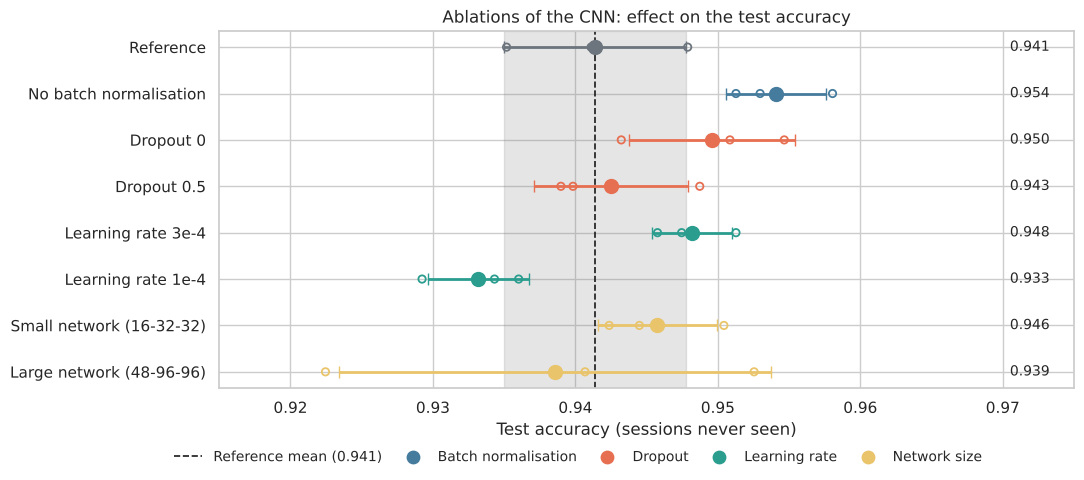

In [5]:
s = summary.reset_index()
ref = s[s.Variant == "Reference"].iloc[0]
pal = {"Reference": "#6c757d", "Batch normalisation": "#457b9d", "Dropout": "#e76f51", "Learning rate": "#2a9d8f", "Network size": "#e9c46a"}

fig, ax = plt.subplots(figsize=(11, 5))
ypos = np.arange(len(s))[::-1]
ax.axvline(ref["Test accuracy"], color="k", ls="--", lw=1.2, label=f"Reference mean ({ref['Test accuracy']:.3f})")
ax.axvspan(ref["Test accuracy"] - ref["Test accuracy std"], ref["Test accuracy"] + ref["Test accuracy std"], color="grey", alpha=0.2)
for yy, (_, row) in zip(ypos, s.iterrows()):
    c = pal[row["Ablation"]]
    seeds = runs.loc[runs.Variant == row["Variant"], "Test accuracy"]
    ax.scatter(seeds, [yy] * len(seeds), s=28, facecolors="none", edgecolors=c, linewidths=1.3, zorder=3)
    ax.errorbar(row["Test accuracy"], yy, xerr=row["Test accuracy std"], fmt="o", ms=10, color=c, capsize=4, lw=2, zorder=4)
    ax.text(0.9705, yy, f"{row['Test accuracy']:.3f}", va="center", fontsize=10)
ax.set_yticks(ypos); ax.set_yticklabels(s["Variant"])
ax.set(xlim=(0.915, 0.975), xlabel="Test accuracy (sessions never seen)", title="Ablations of the CNN: effect on the test accuracy")
for grp, c in list(pal.items())[1:]:
    ax.scatter([], [], color=c, s=80, label=grp)
ax.legend(loc="upper center", bbox_to_anchor=(0.42, -0.14), ncol=5, frameon=False, fontsize=10, columnspacing=1.2)
plt.tight_layout(); plt.savefig(FIG / "dl_25_ablation_test_accuracy.png", dpi=200); plt.show()

## 5. Stability of the training: validation loss per epoch
One thin line per seed. Top: with vs without batch normalisation. Bottom: the three learning rates.

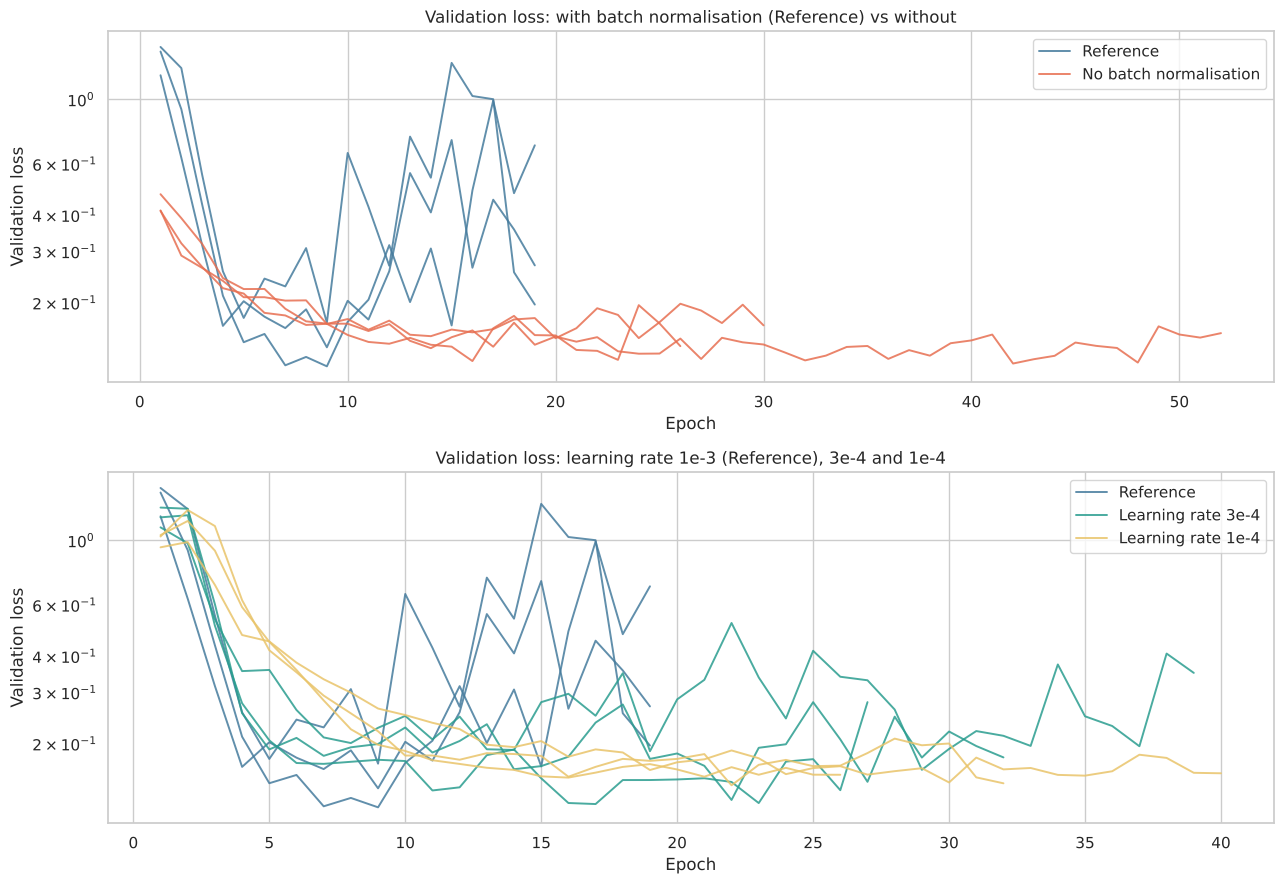

In [6]:
def plot_val(ax, names, colours, title):
    for n, c in zip(names, colours):
        for i, sd in enumerate(SEEDS):
            vl = histories[(n, sd)]["val_loss"]
            ax.plot(np.arange(1, len(vl) + 1), vl, color=c, lw=1.4, alpha=0.85, label=n if i == 0 else None)
    ax.set(title=title, xlabel="Epoch", ylabel="Validation loss", yscale="log")
    ax.legend()

fig, axes = plt.subplots(2, 1, figsize=(13, 9))
plot_val(axes[0], ["Reference", "No batch normalisation"], ["#457b9d", "#e76f51"],
         "Validation loss: with batch normalisation (Reference) vs without")
plot_val(axes[1], ["Reference", "Learning rate 3e-4", "Learning rate 1e-4"], ["#457b9d", "#2a9d8f", "#e9c46a"],
         "Validation loss: learning rate 1e-3 (Reference), 3e-4 and 1e-4")
plt.tight_layout(); plt.savefig(FIG / "dl_26_ablation_validation_curves.png", dpi=200); plt.show()

## 6. Overfitting and instability of each variant
- **Left — overfitting gap:** training accuracy minus test accuracy (final model, dropout off). Larger = the model has memorised more of the training sessions.
- **Right — validation roughness:** mean absolute change of the validation loss between two consecutive epochs. Larger = more unstable training.

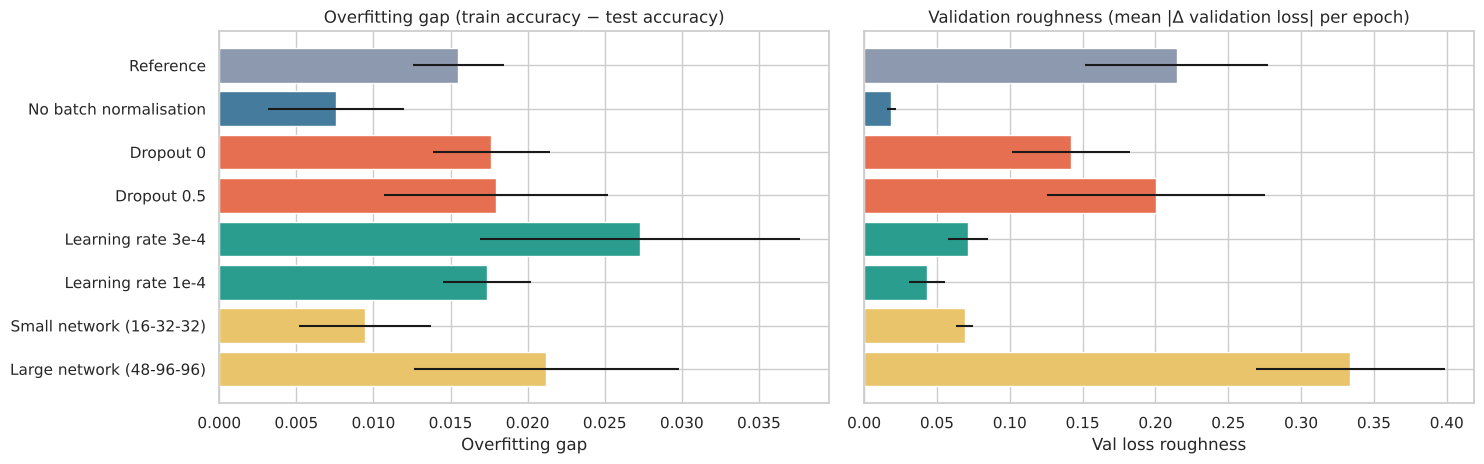

In [7]:
order = s["Variant"].tolist()[::-1]
colours = ["#8d99ae" if v == "Reference" else pal[a] for v, a in zip(s["Variant"], s["Ablation"])][::-1]
gstd = runs.groupby("Variant")[["Overfitting gap", "Val loss roughness"]].std()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, col, title in zip(axes, ["Overfitting gap", "Val loss roughness"],
                          ["Overfitting gap (train accuracy − test accuracy)", "Validation roughness (mean |Δ validation loss| per epoch)"]):
    vals = s.set_index("Variant").loc[order, col]
    ax.barh(order, vals, xerr=gstd.loc[order, col], color=colours)
    ax.set(title=title, xlabel=col)
plt.tight_layout(); plt.savefig(FIG / "dl_27_ablation_overfitting_stability.png", dpi=200); plt.show()

## 7. Conclusions

**How to read the differences.** All 8 variants are between 0.933 and 0.954: the CNN is robust to these choices. With 3 seeds, the reference itself moves by ±0.006, so a difference below about 0.01 is not a real difference.

1. **Batch normalisation is the cause of the unstable training seen in step 4.** Without it, the validation loss is 11 times smoother (roughness 0.214 → 0.019) and never explodes (maximum 1.40 → 0.43). The test accuracy goes from 0.941 to **0.954**, and the 3 seeds without batch normalisation are all above the 3 seeds of the reference. The validation accuracy agrees (0.945 → 0.959), so this is not a choice made on the test set. It is also twice faster per epoch on CPU, but needs more epochs (best epoch 9 → 26).
   *Likely explanation (hypothesis, not proven here):* batch normalisation uses the statistics of the **batch** during training and **stored averages** during validation. The sessions have different noise levels (EDA), so the stored averages do not fit the validation sessions well, and the validation loss jumps from one epoch to the next. The network is small (3 convolution layers) and the input is already normalised, so batch normalisation is not needed to train it.
2. **Dropout has no measurable effect.** 0.950 (no dropout), 0.941 (0.3), 0.943 (0.5): all inside the seed noise, and the overfitting gap stays around 0.02. The model overfits very little: global average pooling leaves only a small dense head (64 units) to regularise.
3. **Learning rate: 1e-3 or 3e-4 are equivalent, 1e-4 is too slow.** 3e-4 gives 0.948 with a smoother validation loss, but needs 2.5 times more epochs. 1e-4 is the only variant clearly **below** the reference (0.933): the training is very smooth but stops on a higher plateau.
4. **The network size does not matter; smaller is enough.** The small network (16,675 parameters, 3.6 times fewer) reaches 0.946 ± 0.004, trains twice faster and is smoother. The large one (132,451 parameters) gives no gain and is the most unstable variant (0.939 ± 0.015). The limit of this problem is not the capacity of the model.

**Decision for the next steps:** remove batch normalisation (the only change with a clear effect). Dropout 0.3 and learning rate 1e-3 are kept.

**Limits.** 3 seeds and a single train/validation/test split by sessions: differences of less than 0.01 are not conclusive. The explanation of the batch-normalisation effect is a hypothesis; it could be tested by measuring the stored averages against the statistics of each session.

Next: `07b_ablations_augmentation.ipynb` (data augmentation and the stripe shortcut).